In [1]:
from pathlib import Path
import csv


folder = (
    Path.home() / "Downloads"
    / "gdc-client_2.3_Windows_x64-py3.8-windows-2019"
    / "gdc-client_2.3_Windows_x64"
)

manifest = folder / "gdc_manifest.2026-10-11.163832.txt"


with open(manifest, encoding="utf-8-sig") as f:
    reader = csv.DictReader(f, delimiter="\t")
    columns = reader.fieldnames
    files = list(reader)


missing = []

for file in files:
    path = folder / file["id"] / file["filename"]

    if not path.is_file() or path.stat().st_size != int(file["size"]):
        missing.append(file)


output = folder / "missing_manifest.txt"

with open(output, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columns, delimiter="\t")
    writer.writeheader()
    writer.writerows(missing)

print("Total files:", len(files))
print("Downloaded files:", len(files) - len(missing))
print("Missing files:", len(missing))
print("Missing manifest saved!")



Total files: 434
Downloaded files: 434
Missing files: 0
Missing manifest saved!


In [2]:
import pandas as pd
from pathlib import Path


files = list(folder.rglob("*.maf.gz"))


downloads = Path.home() / "Downloads"
sheets = list(downloads.rglob("gdc_sample_sheet.2026-10-11.tsv"))

mut_file = next(p for p in sheets if p.parent.name == "mutation")
rna_file = next(p for p in sheets if p.parent.name in ["data_rna", "database"])

mut_ss = pd.read_csv(mut_file, sep="\t")
rna_ss = pd.read_csv(rna_file, sep="\t")

patients = (
    set(mut_ss["Sample ID"].str[:12]) &
    set(rna_ss["Sample ID"].str[:12])
)


keep = [
    "Missense_Mutation", "Nonsense_Mutation",
    "Frame_Shift_Del", "Frame_Shift_Ins",
    "In_Frame_Del", "In_Frame_Ins",
    "Splice_Site", "Translation_Start_Site",
    "Nonstop_Mutation"
]

cad_genes = {

    "CDH1", "CDH2", "CDH3", "CDH11",

    "CDH13", "CDH17",

    "CDHR2", "CDHR5",

    "DSC2", "DSG2",

    "FAT1",

    "PCDH1", "PCDH17", "PCDH18",

    "PCDHGA10",

    "CLSTN1"

}

tp53 = set()
cad = set()


for f in files:
    for df in pd.read_csv(
        f, sep="\t", comment="#",
        usecols=["Hugo_Symbol", "Variant_Classification",
                 "Tumor_Sample_Barcode"],
        chunksize=50000
    ):
        df = df[df["Variant_Classification"].isin(keep)]
        ids = df["Tumor_Sample_Barcode"].str[:12]

        tp53.update(ids[df["Hugo_Symbol"] == "TP53"])
        cad.update(ids[df["Hugo_Symbol"].isin(cad_genes)])



tp53_only = patients & (tp53 - cad)
cad_only = patients & (cad - tp53)
both = patients & tp53 & cad
neither = patients - (tp53 | cad)

print("Total MAF files:", len(files))
print("Total patients:", len(patients))
print("TP53 only:", len(tp53_only))
print("Cadherin only:", len(cad_only))
print("TP53 + Cadherin:", len(both))
print("Neither:", len(neither))
print("Total TP53:", len(tp53& patients))
print("TP53 only:", len(tp53_only))
print("TP53 + cadherin:", len(both))


Total MAF files: 434
Total patients: 404
TP53 only: 107
Cadherin only: 88
TP53 + Cadherin: 76
Neither: 133
Total TP53: 183
TP53 only: 107
TP53 + cadherin: 76


In [4]:
import pandas as pd

CAD_GENES = [

    "CDH1", "CDH11", "CDH13", "CDH17",

    "CDH2", "CDH3", "CDHR2", "CDHR5",

    "CLSTN1", "DSC2", "DSG2", "FAT1",

    "PCDH1", "PCDH17", "PCDH18", "PCDHGA10"

]

assert len(CAD_GENES) == 16

assert "FAT4" not in CAD_GENES

print("Final Cadherin genes:", len(CAD_GENES))

print("FAT4 excluded:", "FAT4" not in CAD_GENES)

print("Total eligible patients:", len(patients))


Final Cadherin genes: 16
FAT4 excluded: True
Total eligible patients: 404


In [5]:
selected_genes = set(CAD_GENES) | {"TP53"}

gene_patients = {g: set() for g in selected_genes}

if "maf" in globals() and isinstance(maf, pd.DataFrame) and {

    "Hugo_Symbol", "Variant_Classification",

    "Tumor_Sample_Barcode"

}.issubset(maf.columns):

    chunks = [maf]

else:

    chunks = (

        chunk

        for f in files

        for chunk in pd.read_csv(

            f,

            sep="\t",

            comment="#",

            usecols=[

                "Hugo_Symbol",

                "Variant_Classification",

                "Tumor_Sample_Barcode"

            ],

            chunksize=50000

        )

    )

for chunk in chunks:

    subset = chunk[

        chunk["Hugo_Symbol"].isin(selected_genes)

        & chunk["Variant_Classification"].isin(keep)

    ].copy()

    subset = subset[

        subset["Tumor_Sample_Barcode"].astype(str).str[13:15] == "01"

    ]

    for gene, group in subset.groupby("Hugo_Symbol"):

        gene_patients[gene].update(

            group["Tumor_Sample_Barcode"].astype(str).str[:12]

        )

patients = set(patients)

tp53 = gene_patients["TP53"] & patients

cad = set().union(*(gene_patients[g] for g in CAD_GENES)) & patients

print("Variant types:", list(keep))

print("TP53 mutated:", len(tp53))

print("Cadherin mutated:", len(cad))



Variant types: ['Missense_Mutation', 'Nonsense_Mutation', 'Frame_Shift_Del', 'Frame_Shift_Ins', 'In_Frame_Del', 'In_Frame_Ins', 'Splice_Site', 'Translation_Start_Site', 'Nonstop_Mutation']
TP53 mutated: 183
Cadherin mutated: 164


In [6]:
patient_data = []

for p in sorted(patients):

    tp53_status = int(p in tp53)

    cad_status = int(p in cad)

    if tp53_status and cad_status:

        group = "Co-mutated"

    elif tp53_status:

        group = "TP53 only"

    elif cad_status:

        group = "Cadherin only"

    else:

        group = "Neither"

    patient_data.append({

        "Patient_ID": p,

        "TP53_Status": tp53_status,

        "Cadherin_Status": cad_status,

        "Mutation_Group": group

    })

patient_df = pd.DataFrame(patient_data)

print(patient_df["Mutation_Group"].value_counts())

print("\nTotal patients:", len(patient_df))

assert patient_df["Patient_ID"].is_unique

assert len(patient_df) == len(patients)

Mutation_Group
Neither          133
TP53 only        107
Cadherin only     88
Co-mutated        76
Name: count, dtype: int64

Total patients: 404


In [12]:
from pathlib import Path

import pandas as pd

rna_dir = Path(

    r"C:\Users\Huawei-com\Downloads\gdc-client_2.3_Windows_x64-py3.8-windows-2019\gdc-client_2.3_Windows_x64\RNA_STAD"

)

rna_files = sorted(rna_dir.rglob("*star_gene_counts.tsv"))

print("Total RNA-seq files:", len(rna_files))

if rna_files:

    print("\nExample file:", rna_files[0].name)

    example = pd.read_csv(

        rna_files[0],

        sep="\t",

        nrows=10

    )

    print("\nColumns:")

    print(example.columns.tolist())

    display(example.head())

Total RNA-seq files: 412

Example file: 49a0c23d-e0e7-4b67-b9f0-527c14105345.rna_seq.augmented_star_gene_counts.tsv

Columns:
['# gene-model: GENCODE v36']


,,,,,,,,# gene-model: GENCODE v36
gene_id,gene_name,gene_type,unstranded,stranded_first,stranded_second,tpm_unstranded,fpkm_unstranded,fpkm_uq_unstranded
N_unmapped,nan,nan,16292846,16292846,16292846,nan,nan,NaN
N_multimapping,nan,nan,11140757,11140757,11140757,nan,nan,NaN
N_noFeature,nan,nan,9692009,51104422,51226935,nan,nan,NaN
N_ambiguous,nan,nan,7474998,1946175,1950592,nan,nan,NaN


In [14]:
from pathlib import Path

import pandas as pd

sample_sheet = (

    Path.home()

    / "Documents"

    / "GitHub"

    / "Basira_Group_A"

    / "data_rna"

    / "gdc_sample_sheet.2026-10-11.tsv"

)

print("Sample sheet found:", sample_sheet.exists())

if sample_sheet.exists():

    metadata = pd.read_csv(sample_sheet, sep="\t")

    print("Total RNA records:", len(metadata))

    print("\nColumns:")

    print(metadata.columns.tolist())

    display(metadata.head())

Sample sheet found: True
Total RNA records: 412

Columns:
['File ID', 'File Name', 'Data Category', 'Data Type', 'Project ID', 'Case ID', 'Sample ID', 'Tissue Type', 'Tumor Descriptor', 'Specimen Type', 'Preservation Method']


,File ID,File Name,Data Category,Data Type,Project ID,Case ID,Sample ID,Tissue Type,Tumor Descriptor,Specimen Type,Preservation Method
0,6a8033f9-8dcd-404a-ad51-b9063f92eff6,e4ccb76d-90cd-48d5-83d7-09d1aab4f439.rna_seq.a...,Transcriptome Profiling,Gene Expression Quantification,TCGA-STAD,TCGA-VQ-A8P8,TCGA-VQ-A8P8-01A,Tumor,Primary,Unknown,Unknown
1,fa2364e1-1d9c-43c3-8836-c4f6b204160d,8246417a-da0a-4330-af7e-cb382a28cc3f.rna_seq.a...,Transcriptome Profiling,Gene Expression Quantification,TCGA-STAD,TCGA-CD-5813,TCGA-CD-5813-01A,Tumor,Primary,Unknown,Unknown
2,0a51d6e0-82de-43b1-b72e-790d57ca9018,5c84144f-68b0-4f96-8b53-5a43a6f83847.rna_seq.a...,Transcriptome Profiling,Gene Expression Quantification,TCGA-STAD,TCGA-BR-6710,TCGA-BR-6710-01A,Tumor,Primary,Solid Tissue,Unknown
3,ff36547a-5887-46af-b0f5-99ea4c1baa96,b13b3f37-a06f-4484-81e3-c0d900d2f35c.rna_seq.a...,Transcriptome Profiling,Gene Expression Quantification,TCGA-STAD,TCGA-CG-4476,TCGA-CG-4476-01A,Tumor,Primary,Unknown,Unknown
4,2aa1c46b-2145-4009-be34-0e93dbfd462e,26080a1b-d146-4ffb-9276-dbc2343b717f.rna_seq.a...,Transcriptome Profiling,Gene Expression Quantification,TCGA-STAD,TCGA-CG-4460,TCGA-CG-4460-01A,Tumor,Primary,Unknown,Unknown


In [15]:
rna_index = pd.DataFrame({

    "File ID": [f.parent.name for f in rna_files],

    "File Name": [f.name for f in rna_files],

    "RNA_Path": [str(f) for f in rna_files]

})

rna_metadata = metadata.copy()

rna_metadata["Patient_ID"] = (

    rna_metadata["Case ID"].astype(str).str[:12]

)

rna_metadata["Sample_Type"] = (

    rna_metadata["Sample ID"].astype(str).str[13:15]

)

rna_matched = rna_metadata.merge(

    rna_index,

    on=["File ID", "File Name"],

    how="left"

)

# Keep eligible patients with primary tumor samples

rna_eligible = rna_matched[

    rna_matched["Patient_ID"].isin(patient_df["Patient_ID"])

    & (rna_matched["Sample_Type"] == "01")

].copy()

print("Total RNA records:", len(rna_metadata))

print("Files matched:", rna_matched["RNA_Path"].notna().sum())

print("Eligible RNA samples:", len(rna_eligible))

print("Unique eligible patients:", rna_eligible["Patient_ID"].nunique())

print("\nMissing RNA files:",

      rna_matched["RNA_Path"].isna().sum())

print("Patients with multiple RNA samples:",

      rna_eligible["Patient_ID"].duplicated().sum())

print("Mutation patients without matched RNA:",

      len(set(patient_df["Patient_ID"]) -

          set(rna_eligible["Patient_ID"])))

display(rna_eligible[[

    "Patient_ID",

    "Sample ID",

    "File ID",

    "RNA_Path"

]].head())

Total RNA records: 412
Files matched: 412
Eligible RNA samples: 404
Unique eligible patients: 404

Missing RNA files: 0
Patients with multiple RNA samples: 0
Mutation patients without matched RNA: 0


,Patient_ID,Sample ID,File ID,RNA_Path
0,TCGA-VQ-A8P8,TCGA-VQ-A8P8-01A,6a8033f9-8dcd-404a-ad51-b9063f92eff6,C:\Users\Huawei-com\Downloads\gdc-client_2.3_W...
1,TCGA-CD-5813,TCGA-CD-5813-01A,fa2364e1-1d9c-43c3-8836-c4f6b204160d,C:\Users\Huawei-com\Downloads\gdc-client_2.3_W...
2,TCGA-BR-6710,TCGA-BR-6710-01A,0a51d6e0-82de-43b1-b72e-790d57ca9018,C:\Users\Huawei-com\Downloads\gdc-client_2.3_W...
3,TCGA-CG-4476,TCGA-CG-4476-01A,ff36547a-5887-46af-b0f5-99ea4c1baa96,C:\Users\Huawei-com\Downloads\gdc-client_2.3_W...
4,TCGA-CG-4460,TCGA-CG-4460-01A,2aa1c46b-2145-4009-be34-0e93dbfd462e,C:\Users\Huawei-com\Downloads\gdc-client_2.3_W...


In [16]:
import pandas as pd

import numpy as np

expression_data = []

patient_ids = []

gene_info = None

samples = rna_eligible.sort_values("Patient_ID")

for i, row in enumerate(samples.itertuples(index=False), 1):

    df = pd.read_csv(

        row.RNA_Path,

        sep="\t",

        comment="#",

        usecols=[

            "gene_id",

            "gene_name",

            "gene_type",

            "tpm_unstranded"

        ]

    )

    # Remove non-gene summary rows

    df = df[df["gene_id"].str.startswith("ENSG", na=False)]

    if gene_info is None:

        gene_info = df[

            ["gene_id", "gene_name", "gene_type"]

        ].copy()

        reference_ids = df["gene_id"].to_numpy()

    else:

        assert np.array_equal(

            df["gene_id"].to_numpy(),

            reference_ids

        ), "Gene order mismatch!"

    expression_data.append(

        pd.to_numeric(

            df["tpm_unstranded"],

            errors="coerce"

        ).to_numpy(dtype="float32")

    )

    patient_ids.append(row.Patient_ID)

    if i % 50 == 0:

        print("Processed:", i, "patients")

expr_tpm = pd.DataFrame(

    np.column_stack(expression_data),

    index=reference_ids,

    columns=patient_ids

)

print("\nExpression Matrix Shape:", expr_tpm.shape)

print("Total patients:", len(expr_tpm.columns))

print("Total genes:", len(expr_tpm.index))

print("Missing values:", expr_tpm.isna().sum().sum())

display(expr_tpm.head())

Processed: 50 patients
Processed: 100 patients
Processed: 150 patients
Processed: 200 patients
Processed: 250 patients
Processed: 300 patients
Processed: 350 patients
Processed: 400 patients

Expression Matrix Shape: (60660, 404)
Total patients: 404
Total genes: 60660
Missing values: 0


,TCGA-3M-AB46,TCGA-3M-AB47,TCGA-B7-5816,TCGA-B7-5818,TCGA-B7-A5TI,TCGA-B7-A5TJ,TCGA-B7-A5TK,TCGA-B7-A5TN,TCGA-BR-4187,TCGA-BR-4191,...,TCGA-VQ-AA6A,TCGA-VQ-AA6B,TCGA-VQ-AA6D,TCGA-VQ-AA6F,TCGA-VQ-AA6G,TCGA-VQ-AA6I,TCGA-VQ-AA6J,TCGA-VQ-AA6K,TCGA-ZA-A8F6,TCGA-ZQ-A9CR
ENSG00000000003.15,19.585100,20.221800,14.551900,17.467600,15.166700,26.680000,46.172199,24.738701,31.283100,73.038803,...,25.389400,88.242897,45.284901,10.952600,15.609900,9.930000,17.490499,19.329300,27.373199,12.284100
ENSG00000000005.6,0.144200,0.041500,1.342600,0.000000,0.000000,0.024600,0.073200,0.177600,0.977800,0.035900,...,0.031000,0.093200,0.000000,0.000000,0.087400,0.088700,0.000000,0.027700,0.173700,0.000000
ENSG00000000419.13,103.803902,49.605099,40.583801,88.038803,94.007004,114.833702,137.567795,129.078201,82.959801,180.841095,...,116.155998,240.512604,193.818405,72.514603,106.848602,73.361099,113.922302,127.553299,70.929398,96.658302
ENSG00000000457.14,4.951600,3.255900,3.403300,3.927000,6.226700,5.604500,5.446300,4.139700,4.310700,9.522100,...,7.493200,5.415700,10.295100,6.831000,9.549700,8.279900,6.620400,10.151500,4.787700,1.676900
ENSG00000000460.17,3.885700,1.196500,2.868400,2.214100,3.586100,3.686300,2.708300,1.599300,2.780000,4.850700,...,9.105900,5.575700,9.269700,3.712000,4.092800,6.826500,4.504700,4.569400,1.560800,1.854900


In [17]:
from pathlib import Path

output_dir = Path("TCGA_STAD_Analysis")

output_dir.mkdir(exist_ok=True)

# Verify patient and gene IDs

assert expr_tpm.index.is_unique

assert expr_tpm.columns.is_unique

assert set(expr_tpm.columns) == set(patient_df["Patient_ID"])

# Save expression matrix

expr_tpm.to_pickle(

    output_dir / "TCGA_STAD_TPM_404.pkl"

)

# Save gene information

gene_info.to_csv(

    output_dir / "Gene_Information.csv",

    index=False

)

# Save mutation groups

patient_df.to_csv(

    output_dir / "Final_Mutation_Groups.csv",

    index=False

)

print("All files saved successfully!")

print("Expression Matrix:", expr_tpm.shape)

print("Mutation Groups:", patient_df.shape)

print("Output folder:", output_dir.resolve())

All files saved successfully!
Expression Matrix: (60660, 404)
Mutation Groups: (404, 4)
Output folder: C:\Users\Huawei-com\TCGA_STAD_Analysis


In [18]:
import pandas as pd

import numpy as np

from pathlib import Path

output_dir = Path("TCGA_STAD_Analysis")

output_dir.mkdir(exist_ok=True)

gene_map = (

    gene_info

    .drop_duplicates("gene_id")

    .set_index("gene_id")["gene_name"]

)

expr_symbols = expr_tpm.copy()

expr_symbols.index = gene_map.reindex(expr_tpm.index).values

expr_symbols = expr_symbols[

    expr_symbols.index.notna()

]

expr_symbols = expr_symbols.groupby(level=0).sum()

print("Gene symbols:", len(expr_symbols))

print("Patients:", len(expr_symbols.columns))

print("GZMA found:", "GZMA" in expr_symbols.index)

print("PRF1 found:", "PRF1" in expr_symbols.index)



Gene symbols: 59427
Patients: 404
GZMA found: True
PRF1 found: True


In [19]:


assert "GZMA" in expr_symbols.index

assert "PRF1" in expr_symbols.index

gzma = expr_symbols.loc["GZMA"]

prf1 = expr_symbols.loc["PRF1"]

cyt_score = np.sqrt(

    (gzma + 0.01) * (prf1 + 0.01)

)

cyt_df = pd.DataFrame({

    "Patient_ID": cyt_score.index,

    "CYT_Score": cyt_score.values

})

cyt_df = patient_df.merge(

    cyt_df,

    on="Patient_ID",

    how="inner",

    validate="one_to_one"

)

assert len(cyt_df) == 404

cyt_df.to_csv(

    output_dir / "CYT_Scores_404.csv",

    index=False

)

print("Total patients:", len(cyt_df))

print("Missing CYT scores:", cyt_df["CYT_Score"].isna().sum())

display(cyt_df.head())

print("\nCYT Score Summary:")

print(cyt_df["CYT_Score"].describe())



Total patients: 404
Missing CYT scores: 0


,Patient_ID,TP53_Status,Cadherin_Status,Mutation_Group,CYT_Score
0,TCGA-3M-AB46,1,0,TP53 only,1.733683
1,TCGA-3M-AB47,0,1,Cadherin only,6.626433
2,TCGA-B7-5816,0,1,Cadherin only,51.103848
3,TCGA-B7-5818,1,1,Co-mutated,26.584236
4,TCGA-B7-A5TI,1,1,Co-mutated,8.662004



CYT Score Summary:
count    404.000000
mean      18.703747
std       21.290691
min        0.789049
25%        5.861639
50%       11.542253
75%       24.292994
max      180.592239
Name: CYT_Score, dtype: float64


In [20]:
import shutil

expr_log2 = np.log2(expr_symbols + 1)

expr_log2.index.name = "GeneSymbol"

expr_log2.to_csv(

    output_dir / "TCGA_STAD_log2TPM.tsv",

    sep="\t"

)

print("Expression matrix saved!")

print("Shape:", expr_log2.shape)

print("\nRscript location:")

print(shutil.which("Rscript"))



Expression matrix saved!
Shape: (59427, 404)

Rscript location:
None


In [21]:
from pathlib import Path

import subprocess

r_folder = Path(r"C:\Program Files\R")

r_scripts = list(r_folder.glob("R-*/bin/Rscript.exe"))

if r_scripts:

    rscript = str(r_scripts[-1])

    print("R found:", rscript)

    result = subprocess.run(

        [rscript, "--version"],

        capture_output=True,

        text=True

    )

    print(result.stdout or result.stderr)

else:

    print("R not found!")

R found: C:\Program Files\R\R-4.6.2\bin\Rscript.exe
Rscript (R) version 4.6.2 (2026-10-29)



In [23]:
import subprocess

install_code = """

options(repos = c(CRAN = "https://cloud.r-project.org"))

user_lib <- file.path(path.expand("~"), "R_libs")

dir.create(

    user_lib,

    recursive = TRUE,

    showWarnings = FALSE

)

.libPaths(c(user_lib, .libPaths()))

cat("Library path:", .libPaths()[1], "\\n")

if (!requireNamespace("remotes", quietly = TRUE)) {

    install.packages("remotes", lib = user_lib)

}

if (!requireNamespace("curl", quietly = TRUE)) {

    install.packages("curl", lib = user_lib)

}

if (!requireNamespace("MCPcounter", quietly = TRUE)) {

    remotes::install_github(

        "ebecht/MCPcounter",

        subdir = "Source",

        lib = user_lib,

        dependencies = NA,

        upgrade = "never",

        build = FALSE

    )

}

cat("MCPcounter installed:",

    requireNamespace("MCPcounter", quietly = TRUE), "\\n")

"""

script_path = output_dir / "install_MCPcounter_fixed.R"

script_path.write_text(install_code, encoding="utf-8")

result = subprocess.run(

    [rscript, str(script_path)],

    capture_output=True,

    text=True

)

print(result.stdout[-4000:])

print(result.stderr[-4000:])

print("Return code:", result.returncode)

Library path: C:/Users/Huawei-com/Documents/R_libs 
package 'remotes' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Huawei-com\AppData\Local\Temp\RtmpkBea3k\downloaded_packages
package 'curl' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\Huawei-com\AppData\Local\Temp\RtmpkBea3k\downloaded_packages
MCPcounter installed: TRUE 

trying URL 'https://cloud.r-project.org/bin/windows/contrib/4.6/remotes_2.5.0.zip'
Content type 'application/zip' length 439980 bytes (429 KB)
downloaded 429 KB

trying URL 'https://cloud.r-project.org/bin/windows/contrib/4.6/curl_8.1.0.zip'
Content type 'application/zip' length 3694955 bytes (3.5 MB)
downloaded 3.5 MB

* installing *source* package 'MCPcounter' ...
** this is package 'MCPcounter' version '1.2.0'
** using staged installation
** R
** data
*** moving datasets to lazyload DB
** byte-compile and prepare package for lazy loading
** help
*** installing help indic

In [24]:
import subprocess

import pandas as pd

from pathlib import Path

input_file = output_dir / "TCGA_STAD_log2TPM.tsv"

output_file = output_dir / "MCP_CD8_Scores.csv"

r_code = f'''

.libPaths(c(file.path(path.expand("~"), "R_libs"), .libPaths()))

library(MCPcounter)

# Read expression matrix

expr <- read.delim(

    "{input_file.resolve().as_posix()}",

    row.names = 1,

    check.names = FALSE

)

expr <- as.matrix(expr)

# Calculate MCP-counter scores

scores <- MCPcounter.estimate(

    expr,

    featuresType = "HUGO_symbols"

)

# Extract CD8 T-cell scores

stopifnot("CD8 T cells" %in% rownames(scores))

cd8 <- data.frame(

    Patient_ID = colnames(scores),

    CD8_Score = as.numeric(scores["CD8 T cells", ])

)

# Save results

write.csv(

    cd8,

    "{output_file.resolve().as_posix()}",

    row.names = FALSE

)

print(summary(cd8$CD8_Score))

print(nrow(cd8))

'''

script_path = output_dir / "calculate_CD8.R"

script_path.write_text(r_code, encoding="utf-8")

result = subprocess.run(

    [rscript, str(script_path)],

    capture_output=True,

    text=True

)

print("Return code:", result.returncode)

print(result.stdout[-3000:])

print(result.stderr[-3000:])

if result.returncode == 0:

    cd8_df = pd.read_csv(output_file)

    assert len(cd8_df) == 404

    assert cd8_df["Patient_ID"].is_unique

    assert cd8_df["CD8_Score"].notna().all()

    cd8_final = patient_df.merge(

        cd8_df,

        on="Patient_ID",

        validate="one_to_one"

    )

    print("Total patients:", len(cd8_final))

    print("Missing scores:", cd8_final["CD8_Score"].isna().sum())

    display(cd8_final.head())

Return code: 0
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.02063 0.69342 1.30643 1.46500 1.99396 5.92743 
[1] 404

Loading required package: curl
Using libcurl 8.14.1-DEV with Schannel

Total patients: 404
Missing scores: 0


,Patient_ID,TP53_Status,Cadherin_Status,Mutation_Group,CD8_Score
0,TCGA-3M-AB46,1,0,TP53 only,0.305795
1,TCGA-3M-AB47,0,1,Cadherin only,0.681674
2,TCGA-B7-5816,0,1,Cadherin only,0.870108
3,TCGA-B7-5818,1,1,Co-mutated,1.725480
4,TCGA-B7-A5TI,1,1,Co-mutated,0.740453


In [25]:
import subprocess

from pathlib import Path

r_code = r'''

user_lib <- file.path(path.expand("~"), "R_libs")

dir.create(user_lib, recursive = TRUE, showWarnings = FALSE)

.libPaths(c(user_lib, .libPaths()))

if (!requireNamespace("estimate", quietly = TRUE)) {

    install.packages(

        "https://download.r-forge.r-project.org/src/contrib/estimate_1.0.13.tar.gz",

        repos = NULL,

        type = "source",

        lib = user_lib

    )

}

cat("ESTIMATE installed:",

    requireNamespace("estimate", quietly = TRUE), "\n")

stopifnot(requireNamespace("estimate", quietly = TRUE))

'''

script_path = output_dir / "install_ESTIMATE.R"

script_path.write_text(r_code, encoding="utf-8")

result = subprocess.run(

    [rscript, str(script_path.resolve())],

    capture_output=True,

    text=True,

    errors="replace"

)

print(result.stdout[-3000:])

print(result.stderr[-3000:])

print("Return code:", result.returncode)



ESTIMATE installed: TRUE 

trying URL 'https://download.r-forge.r-project.org/src/contrib/estimate_1.0.13.tar.gz'
Content type 'application/x-gzip' length 3845282 bytes (3.7 MB)
downloaded 3.7 MB

* installing *source* package 'estimate' ...
** this is package 'estimate' version '1.0.13'
** using staged installation
** R
** data
*** moving datasets to lazyload DB
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (estimate)

Return code: 0


In [26]:
import subprocess

input_file = output_dir / "TCGA_STAD_log2TPM.tsv"

filtered_file = output_dir / "ESTIMATE_Filtered.gct"

scores_file = output_dir / "ESTIMATE_Results.gct"

estimate_file = output_dir / "ESTIMATE_Immune_Scores.csv"

assert input_file.exists(), "Expression matrix not found!"

r_code = r'''

.libPaths(c(

    file.path(path.expand("~"), "R_libs"),

    .libPaths()

))

library(estimate)

args <- commandArgs(trailingOnly = TRUE)

input_file <- args[1]

filtered_file <- args[2]

scores_file <- args[3]

output_file <- args[4]

filterCommonGenes(

    input.f = input_file,

    output.f = filtered_file,

    id = "GeneSymbol"

)

estimateScore(

    input.ds = filtered_file,

    output.ds = scores_file,

    platform = "illumina"

)

scores <- read.delim(

    scores_file,

    skip = 2,

    row.names = 1,

    check.names = FALSE

)

stopifnot("ImmuneScore" %in% rownames(scores))

patient_ids <- setdiff(

    colnames(scores),

    "Description"

)

immune_df <- data.frame(

    Patient_ID = patient_ids,

    ESTIMATE_Immune_Score = as.numeric(

        scores["ImmuneScore", patient_ids]

    )

)

stopifnot(nrow(immune_df) == 404)

stopifnot(all(is.finite(immune_df$ESTIMATE_Immune_Score)))

write.csv(

    immune_df,

    output_file,

    row.names = FALSE

)

cat("ESTIMATE scores calculated successfully!\n")

cat("Total patients:", nrow(immune_df), "\n")

print(summary(immune_df$ESTIMATE_Immune_Score))

'''

script_path = output_dir / "calculate_ESTIMATE.R"

script_path.write_text(r_code, encoding="utf-8")

result = subprocess.run(

    [

        rscript,

        str(script_path.resolve()),

        str(input_file.resolve()),

        str(filtered_file.resolve()),

        str(scores_file.resolve()),

        str(estimate_file.resolve())

    ],

    capture_output=True,

    text=True,

    errors="replace"

)

print("Return code:", result.returncode)

print(result.stdout[-4000:])

print(result.stderr[-4000:])

if result.returncode != 0:

    raise RuntimeError("ESTIMATE calculation failed.")



Return code: 0
[1] "Merged dataset includes 9911 genes (501 mismatched)."
[1] "1 gene set: StromalSignature  overlap= 136"
[1] "2 gene set: ImmuneSignature  overlap= 140"
ESTIMATE scores calculated successfully!
Total patients: 404 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -990.0   553.3  1192.6  1166.7  1737.1  3125.5 




In [31]:
import pandas as pd

import numpy as np

estimate_df = pd.read_csv(

    output_dir / "ESTIMATE_Immune_Scores.csv"

)
estimate_df["Patient_ID"] = estimate_df["Patient_ID"].str.replace(".","-", regex=False)

cd8_df = pd.read_csv(

    output_dir / "MCP_CD8_Scores.csv"

)

cyt_scores = cyt_df[

    ["Patient_ID", "CYT_Score"]

].copy()

final_df = patient_df.merge(

    estimate_df,

    on="Patient_ID",

    validate="one_to_one"

)

final_df = final_df.merge(

    cd8_df,

    on="Patient_ID",

    validate="one_to_one"

)

final_df = final_df.merge(

    cyt_scores,

    on="Patient_ID",

    validate="one_to_one"

)

score_columns = [

    "ESTIMATE_Immune_Score",

    "CD8_Score",

    "CYT_Score"

]

assert len(final_df) == 404

assert final_df["Patient_ID"].is_unique

assert np.isfinite(final_df[score_columns].to_numpy()).all()

print("Total patients:", len(final_df))

print("\nMissing values:")

print(final_df[score_columns].isna().sum())

display(final_df.head())

final_df.to_csv(

    output_dir / "Final_Immune_Scores_404.csv",

    index=False

)

print("\nFinal immune scores saved successfully!")



Total patients: 404

Missing values:
ESTIMATE_Immune_Score    0
CD8_Score                0
CYT_Score                0
dtype: int64


,Patient_ID,TP53_Status,Cadherin_Status,Mutation_Group,ESTIMATE_Immune_Score,CD8_Score,CYT_Score
0,TCGA-3M-AB46,1,0,TP53 only,240.893739,0.305795,1.733683
1,TCGA-3M-AB47,0,1,Cadherin only,1236.668758,0.681674,6.626433
2,TCGA-B7-5816,0,1,Cadherin only,1887.003801,0.870108,51.103848
3,TCGA-B7-5818,1,1,Co-mutated,1765.291934,1.725480,26.584236
4,TCGA-B7-A5TI,1,1,Co-mutated,746.001786,0.740453,8.662004



Final immune scores saved successfully!


In [33]:
score_columns = [

    "ESTIMATE_Immune_Score",

    "CD8_Score",

    "CYT_Score"

]

group_summary = final_df.groupby(

    "Mutation_Group"

)[score_columns].agg(

    ["count", "mean", "median", "std"]

)

print("Immune Scores by Mutation Group:")

display(group_summary)

group_summary.to_csv(

    output_dir / "Immune_Group_Summary.csv"

)

print("\nGroup counts:")

print(final_df["Mutation_Group"].value_counts())

print("\nDescriptive statistics completed!")



Immune Scores by Mutation Group:


ESTIMATE_Immune_Score                                        \
                               count         mean       median         std   
Mutation_Group                                                               
Cadherin only                     88  1398.707024  1505.436921  764.391915   
Co-mutated                        76  1042.219965   927.814243  774.891626   
Neither                          133  1332.455035  1417.586953  863.702987   
TP53 only                        107   858.096579   864.705598  745.584773   

               CD8_Score                               CYT_Score             \
                   count      mean    median       std     count       mean   
Mutation_Group                                                                
Cadherin only         88  1.477924  1.237711  0.921551        88  23.104454   
Co-mutated            76  1.365654  1.241977  0.859378        76  17.333656   
Neither              133  1.592388  1.465713  1.022686       133  20.995249   
TP53 only            107  1.366602  1.193835  1.069660       107  13.209310   

                                      
                   median        std  
Mutation_Group                        
Cadherin only   17.343130  21.402590  
Co-mutated      11.825069  17.939932  
Neither         13.090999  24.608870  
TP53 only        8.960176  17.637020


Group counts:
Mutation_Group
Neither          133
TP53 only        107
Cadherin only     88
Co-mutated        76
Name: count, dtype: int64

Descriptive statistics completed!


In [37]:
from scipy.stats import kruskal

from statsmodels.stats.multitest import multipletests

scores = [

    "ESTIMATE_Immune_Score",

    "CD8_Score",

    "CYT_Score"

]

results = []

for score in scores:

    groups = [

        data[score].dropna()

        for _, data in final_df.groupby("Mutation_Group")

    ]

    h, p = kruskal(*groups)

    results.append([score, h, p])

stats_df = pd.DataFrame(

    results,

    columns=["Endpoint", "H_statistic", "P_value"]

)

stats_df["Adjusted_P"] = multipletests(

    stats_df["P_value"],

    method="holm"

)[1]

stats_df["Significant"] = stats_df["Adjusted_P"] < 0.05

display(stats_df)

stats_df.to_csv(

    output_dir / "Statistical_Test_Results.csv",

    index=False

)


,Endpoint,H_statistic,P_value,Adjusted_P,Significant
0,ESTIMATE_Immune_Score,27.932859,0.000004,0.000011,True
1,CD8_Score,5.172711,0.159579,0.159579,False
2,CYT_Score,24.243774,0.000022,0.000044,True


In [ ]:
from scipy.stats import mannwhitneyu

from statsmodels.stats.multitest import multipletests

results = []

for score in score_columns:

    a = final_df.loc[

        final_df["Mutation_Group"] == "Co-mutated", score

    ]

    for group in ["TP53 only", "Cadherin only", "Neither"]:

        b = final_df.loc[

            final_df["Mutation_Group"] == group, score

        ]

        stat, p = mannwhitneyu(

            a, b, alternative="two-sided"

        )

        results.append([score, group, p])

posthoc_df = pd.DataFrame(

    results,

    columns=["Endpoint", "Compared_with", "P_value"]

)

posthoc_df["Adjusted_P"] = multipletests(

    posthoc_df["P_value"],

    method="holm"

)[1]

posthoc_df["Significant"] = (

    posthoc_df["Adjusted_P"] < 0.05

)

display(posthoc_df)

posthoc_df.to_csv(

    output_dir / "Posthoc_Results.csv",

    index=False

)

In [38]:
import statsmodels.formula.api as smf

from statsmodels.stats.multitest import multipletests

import numpy as np

results = []

for score in score_columns:

    data = final_df.copy()

    data["Outcome"] = (

        np.log1p(data[score])

        if score == "CYT_Score"

        else data[score]

    )

    model = smf.ols(

        "Outcome ~ TP53_Status * Cadherin_Status",

        data=data

    ).fit(cov_type="HC3")

    term = "TP53_Status:Cadherin_Status"

    results.append([

        score,

        model.params[term],

        model.pvalues[term]

    ])

interaction_df = pd.DataFrame(

    results,

    columns=["Endpoint", "Interaction_Coefficient", "P_value"]

)

interaction_df["Adjusted_P"] = multipletests(

    interaction_df["P_value"], method="holm"

)[1]

interaction_df["Significant"] = interaction_df["Adjusted_P"] < 0.05

display(interaction_df)

interaction_df.to_csv(

    output_dir / "Interaction_Results.csv", index=False

)



,Endpoint,Interaction_Coefficient,P_value,Adjusted_P,Significant
0,ESTIMATE_Immune_Score,117.871397,0.461463,1.0,False
1,CD8_Score,0.113516,0.562022,1.0,False
2,CYT_Score,0.130799,0.454653,1.0,False


In [41]:
from scipy.stats import mannwhitneyu

results = []

for score in score_columns:

    low, high = final_df[score].quantile([0.01, 0.99])

    data = final_df[final_df[score].between(low, high)]

    co = data[data["Mutation_Group"] == "Co-mutated"][score]

    for group in ["TP53 only", "Cadherin only", "Neither"]:

        other = data[data["Mutation_Group"] == group][score]

        _, p = mannwhitneyu(

            co, other, alternative="two-sided"

        )

        results.append([score, group, len(co), len(other), p])

sensitivity_df = pd.DataFrame(

    results,

    columns=["Endpoint", "Compared_with", "N_Co", "N_Other", "P_value"]

)

sensitivity_df["Adjusted_P"] = multipletests(

    sensitivity_df["P_value"],

    method="holm"

)[1]

sensitivity_df["Significant"] = (

    sensitivity_df["Adjusted_P"] < 0.05

)

display(sensitivity_df)

sensitivity_df.to_csv(

    output_dir / "Sensitivity_Posthoc.csv",

    index=False

)



,Endpoint,Compared_with,N_Co,N_Other,P_value,Adjusted_P,Significant
0,ESTIMATE_Immune_Score,TP53 only,75,103,0.501800,1.000000,False
1,ESTIMATE_Immune_Score,Cadherin only,75,86,0.001161,0.010452,True
2,ESTIMATE_Immune_Score,Neither,75,130,0.019772,0.138406,False
3,CD8_Score,TP53 only,74,103,0.439375,1.000000,False
4,CD8_Score,Cadherin only,74,86,0.450484,1.000000,False
5,CD8_Score,Neither,74,131,0.143342,0.716712,False
6,CYT_Score,TP53 only,73,103,0.002783,0.022262,True
7,CYT_Score,Cadherin only,73,87,0.100810,0.604862,False
8,CYT_Score,Neither,73,131,0.806506,1.000000,False


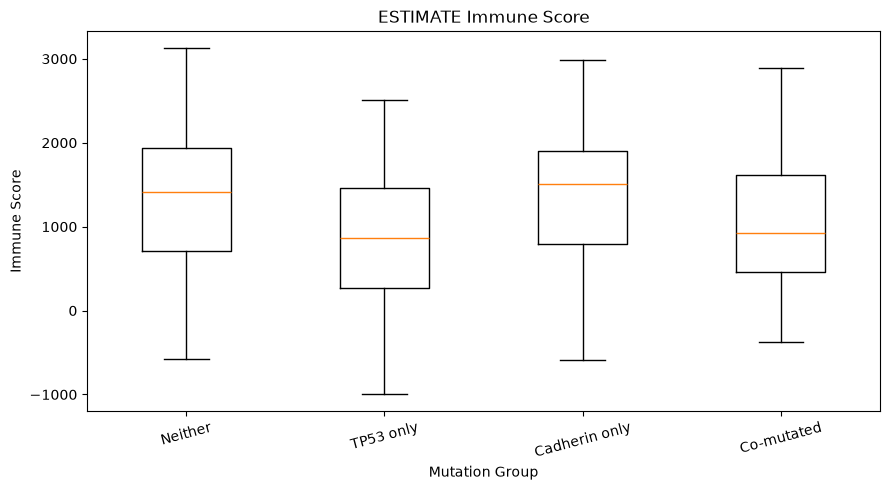

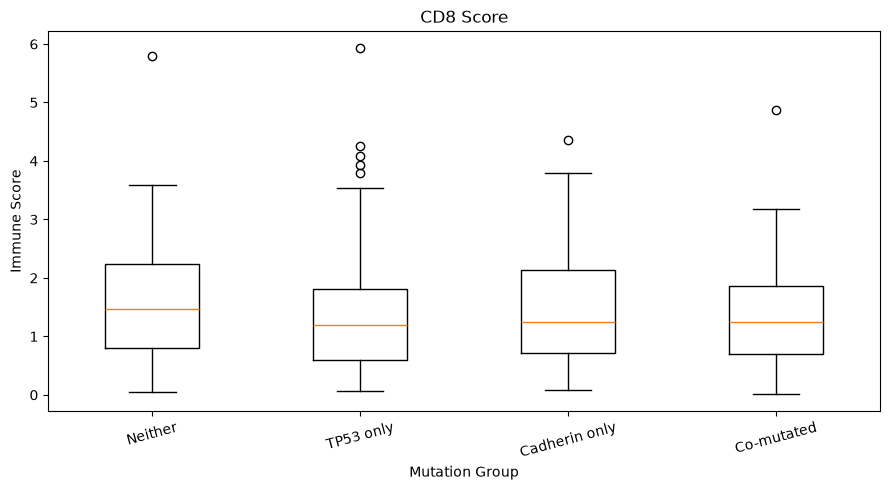

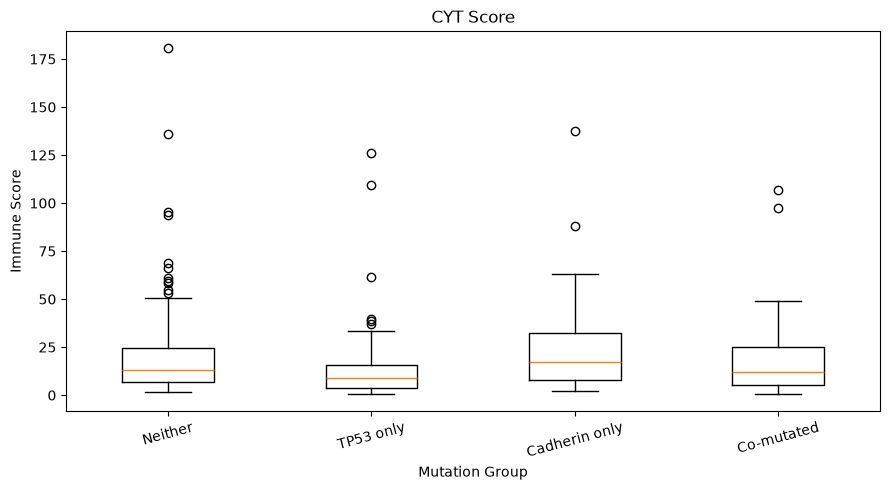

All figures saved successfully!


In [2]:
import matplotlib.pyplot as plt

groups = [

    "Neither",

    "TP53 only",

    "Cadherin only",

    "Co-mutated"

]

for score in scores:

    values = [

        final_df.loc[

            final_df["Mutation_Group"] == group,

            score

        ].dropna()

        for group in groups

    ]

    plt.figure(figsize=(9, 5))

    plt.boxplot(values, tick_labels=groups)

    plt.title(score.replace("_", " "))

    plt.xlabel("Mutation Group")

    plt.ylabel("Immune Score")

    plt.xticks(rotation=15)

    plt.tight_layout()

    plt.savefig(

        output_dir / f"{score}_Final.png",

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()

print("All figures saved successfully!")

In [4]:
from scipy.stats import kruskal

from statsmodels.stats.multitest import multipletests

results = []

for score in scores:

    low, high = final_df[score].quantile([0.01, 0.99])

    data = final_df[final_df[score].between(low, high)]

    groups_data = [

        g[score].dropna()

        for _, g in data.groupby("Mutation_Group")

    ]

    h, p = kruskal(*groups_data)

    results.append([score, len(data), h, p])

sensitivity_global = pd.DataFrame(

    results,

    columns=["Endpoint", "N", "H_statistic", "P_value"]

)

sensitivity_global["Adjusted_P"] = multipletests(

    sensitivity_global["P_value"], method="holm"

)[1]

sensitivity_global["Significant"] = (

    sensitivity_global["Adjusted_P"] < 0.05

)

display(sensitivity_global)

sensitivity_global.to_csv(

    output_dir / "Sensitivity_Global.csv",

    index=False

)

,Endpoint,N,H_statistic,P_value,Adjusted_P,Significant
0,ESTIMATE_Immune_Score,394,24.125812,0.000024,0.000058,True
1,CD8_Score,394,5.590528,0.133323,0.133323,False
2,CYT_Score,394,24.546227,0.000019,0.000058,True
